# 04 Logistic Regression、訓練列的選擇、ablation 與其他比較

LR 的訓練列來自 train 內的 snapshot：特徵只用該年以前的資料，和 validation 的設定相同。比較三種訓練列（`TRAIN_MODES`）：

| mode | 訓練列 |
|---|---|
| `all` | 2011、2012 年的所有評論 |
| `pseudo_cold` | 2009–2012 年中，食譜在該年以前**沒有任何評論**的列（和 cold 列相同的情況） |
| `pseudo_cold_w` | 同上，每列權重 1/√(該 user 的列數)，避免重度 user 主導 |

相似度特徵改用**相對版** `wa_* − p_u`（只保留這道食譜和 user 平常的差距）。
選出 `TRAIN_MODE`、`C`，連同 `CLASS_WEIGHT`（固定為 None）與 `LAM_USER` 存到 `results/params.json`。
**以 validation cold 列的 log loss 選**：輸出是機率，而不同 C 之間 AUC 只差約 0.001，log loss 卻差很多。

In [14]:
%load_ext autoreload
%autoreload 2

import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import *
from features import (RecipeSets, build_features, group_columns, load_interactions, load_recipes,
                      make_snapshot, user_prior, weighted_average, year_snapshot)
from models import (VARIANTS, baseline_constant, fit_lr, lr_coefficients, predict, training_set,
                    tune_beta, tune_weighted_average)
from evaluation import auc, compare, evaluate, log_loss, mean_ci, pretty
from ranking import ranking_metrics, sample_candidates

warnings.filterwarnings("ignore", category=FutureWarning)  # pandas copy-on-write notices
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.4f}".format)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [15]:
t0 = time.time()
train, val, test = load_interactions()
recipes = load_recipes()
print(f"loaded in {time.time() - t0:.0f}s: train {len(train):,}, validation {len(val):,}, test {len(test):,}, recipes {len(recipes):,}")

loaded in 10s: train 683,996, validation 22,933, test 22,224, recipes 178,265


In [16]:
P = load_params("BETA", "MAX_DF", "WA")
BETA, MAX_DF, WA = P["BETA"], P["MAX_DF"], P["WA"]
LAM_USER = WA["J1-T"]["lam"]
MODES = list(TRAIN_MODES)

rsets = RecipeSets(recipes)
snap_val = make_snapshot("validation", train, val, rsets, H=H, max_df=MAX_DF)
cold_val = snap_val.targets.cold.values == 1
y_val = snap_val.targets[f"y_{LABEL}"].values
u_val = snap_val.targets.u.values
print(f"validation snapshot: {snap_val.n:,} rows ({cold_val.sum():,} cold), {len(snap_val.pairs):,} pairs")
prior_val = user_prior(snap_val, LABEL, BETA)

validation snapshot: 22,933 rows (6,410 cold), 1,749,741 pairs


In [17]:
def snapshot_keys(mode, which):
    m = TRAIN_MODES[mode]
    return [(yr, m["cold_only"]) for yr in m[which]]

t0 = time.time()
snaps_lr = {key: year_snapshot(train, key[0], rsets, cold_only=key[1], H=H, max_df=MAX_DF)
            for key in sorted({k for mode in MODES for which in ("years_val", "years_test") for k in snapshot_keys(mode, which)})}
for s in snaps_lr.values():
    print(f"{s.name}: {s.n:,} rows, positive share {s.targets.y_eq5.mean():.3f}, {len(s.pairs):,} pairs")
X_lr = {key: build_features(s, recipes, LABEL, BETA, WA, LAM_USER) for key, s in snaps_lr.items()}
X_val = build_features(snap_val, recipes, LABEL, BETA, WA, LAM_USER)

def mode_train_set(mode, X=X_lr, label=LABEL):
    return training_set(snaps_lr, X, snapshot_keys(mode, "years_val"), label, TRAIN_MODES[mode]["weighted"])
print(f"{X_val.shape[1]} features, {time.time() - t0:.0f}s")

train2009-cold: 28,265 rows, positive share 0.754, 2,012,362 pairs
train2010-cold: 16,997 rows, positive share 0.770, 1,345,563 pairs
train2011: 39,901 rows, positive share 0.780, 2,861,608 pairs
train2011-cold: 11,765 rows, positive share 0.772, 996,911 pairs
train2012: 30,251 rows, positive share 0.782, 2,256,204 pairs
train2012-cold: 8,295 rows, positive share 0.776, 737,363 pairs
51 features, 11s


In [18]:
rows = []
for mode in MODES:
    X_tr, y_tr, w_tr = mode_train_set(mode)
    for C in C_GRID:
        # class_weight="balanced" is left out: it pulls the probabilities toward 0.5 (validation log loss
        # 0.586 vs 0.533 for the constant B0) while changing AUC by about 0.0001
        for cw in (None,):
            p = predict(fit_lr(X_tr, y_tr, C=C, class_weight=cw, sample_weight=w_tr), X_val)[cold_val]
            rows.append({"mode": mode, "rows": len(X_tr), "positive share": y_tr.mean(),
                         "C": C, "class_weight": cw or "none", "AUC": auc(y_val[cold_val], p),
                         "LogLoss": log_loss(y_val[cold_val], p)})
# Selected by log loss: the output is a probability, and across C the AUC moves by ~0.001 while
# strong regularization (small C) makes the probabilities badly calibrated.
c_table = pd.DataFrame(rows).sort_values("LogLoss").reset_index(drop=True)
c_table.to_csv(RESULTS / "tune_lr_mode_C.csv", index=False)
best_per_mode = c_table.groupby("mode", sort=False).head(1).set_index("mode")
TRAIN_MODE, C_BEST = c_table["mode"][0], float(c_table.C[0])
CW = None if c_table.class_weight[0] == "none" else "balanced"
save_params(TRAIN_MODE=TRAIN_MODE, C=C_BEST, CLASS_WEIGHT=CW, LAM_USER=LAM_USER)
print("TRAIN_MODE =", TRAIN_MODE, "C =", C_BEST, "class_weight =", CW)
best_per_mode.style.format({"C": "{:g}", "AUC": "{:.4f}", "LogLoss": "{:.4f}", "positive share": "{:.3f}", "rows": "{:,}"})

TRAIN_MODE = pseudo_cold C = 0.1 class_weight = None


,rows,positive share,C,class_weight,AUC,LogLoss
mode,,,,,,
pseudo_cold,"65,322",0.764,0.1,none,0.7335,0.4666
pseudo_cold_w,"65,322",0.764,0.003,none,0.7304,0.4682
all,"70,152",0.780,0.0003,none,0.7311,0.4685


In [19]:
# Each mode at its own best C: paired difference to "all"
mode_preds = {}
for mode, r in best_per_mode.iterrows():
    X_tr, y_tr, w_tr = mode_train_set(mode)
    cw = None if r.class_weight == "none" else "balanced"
    mode_preds[f"LR ({mode})"] = predict(fit_lr(X_tr, y_tr, C=r.C, class_weight=cw, sample_weight=w_tr), X_val)[cold_val]
cmp_mode = compare(mode_preds, "LR (all)", y_val[cold_val], u_val[cold_val], n_boot=N_BOOT)
cmp_mode.to_csv(RESULTS / "val_train_modes.csv")
pretty(cmp_mode)[["ΔAUC", "p_not_better_AUC", "ΔLogLoss", "p_not_better_LogLoss"]]

,ΔAUC,p_not_better_AUC,ΔLogLoss,p_not_better_LogLoss
model,,,,
LR (pseudo_cold),"+0.0023 [-0.0005, +0.0058]",0.058,"-0.0018 [-0.0042, +0.0004]",0.064
LR (pseudo_cold_w),"-0.0007 [-0.0034, +0.0019]",0.690,"-0.0003 [-0.0021, +0.0016]",0.415


In [20]:
def wa_predictions(snap, prior, label=LABEL):
    return {name: weighted_average(snap, prm["sim"], label, prior, prm["k"], prm["alpha"], prm["lam"])
            for name, prm in WA.items()}

X_tr, y_tr, w_tr = mode_train_set(TRAIN_MODE)
lr = fit_lr(X_tr, y_tr, C=C_BEST, class_weight=CW, sample_weight=w_tr)
preds_val = {"B0": baseline_constant(snap_val, LABEL), "B1": prior_val, **wa_predictions(snap_val, prior_val),
             "LR": predict(lr, X_val)}
ev = {k: v[cold_val] for k, v in preds_val.items()}
res_val = evaluate(ev, y_val[cold_val], u_val[cold_val], n_boot=N_BOOT)
res_val.to_csv(RESULTS / "val_main.csv")
pretty(res_val)

,AUC,LogLoss,Brier
model,,,
B0,"0.5000 [0.5000, 0.5000]","0.5331 [0.5046, 0.5637]","0.1743 [0.1613, 0.1881]"
B1,"0.7252 [0.6902, 0.7605]","0.4722 [0.4404, 0.5048]","0.1530 [0.1409, 0.1657]"
J1,"0.7305 [0.6964, 0.7660]","0.4678 [0.4348, 0.5008]","0.1507 [0.1384, 0.1634]"
J1-T,"0.7305 [0.6964, 0.7659]","0.4677 [0.4347, 0.5007]","0.1507 [0.1384, 0.1634]"
J2,"0.7297 [0.6960, 0.7639]","0.4690 [0.4360, 0.5020]","0.1511 [0.1390, 0.1639]"
J2-T,"0.7296 [0.6960, 0.7639]","0.4689 [0.4360, 0.5020]","0.1511 [0.1390, 0.1639]"
C1,"0.7302 [0.6963, 0.7653]","0.4679 [0.4347, 0.5010]","0.1508 [0.1386, 0.1635]"
C1-T,"0.7302 [0.6965, 0.7652]","0.4679 [0.4347, 0.5009]","0.1508 [0.1386, 0.1635]"
C2,"0.7297 [0.6958, 0.7641]","0.4684 [0.4356, 0.5015]","0.1511 [0.1390, 0.1640]"


In [21]:
cmp_val = compare({k: v for k, v in ev.items() if k != "B0"}, "B1", y_val[cold_val], u_val[cold_val], n_boot=N_BOOT)
cmp_val.to_csv(RESULTS / "val_main_vs_B1.csv")
pretty(cmp_val)[["ΔAUC", "p_not_better_AUC", "ΔLogLoss", "p_not_better_LogLoss"]]

,ΔAUC,p_not_better_AUC,ΔLogLoss,p_not_better_LogLoss
model,,,,
J1,"+0.0053 [+0.0000, +0.0113]",0.025,"-0.0044 [-0.0096, -0.0001]",0.022
J1-T,"+0.0053 [+0.0000, +0.0113]",0.025,"-0.0044 [-0.0095, -0.0002]",0.021
J2,"+0.0044 [-0.0017, +0.0109]",0.086,"-0.0032 [-0.0088, +0.0018]",0.126
J2-T,"+0.0044 [-0.0017, +0.0108]",0.086,"-0.0033 [-0.0088, +0.0017]",0.118
C1,"+0.0049 [-0.0001, +0.0105]",0.027,"-0.0042 [-0.0091, -0.0002]",0.022
C1-T,"+0.0049 [-0.0001, +0.0105]",0.027,"-0.0043 [-0.0090, -0.0003]",0.020
C2,"+0.0045 [-0.0009, +0.0104]",0.057,"-0.0038 [-0.0088, +0.0004]",0.049
C2-T,"+0.0044 [-0.0009, +0.0103]",0.057,"-0.0038 [-0.0086, +0.0003]",0.045
LR,"+0.0082 [-0.0006, +0.0181]",0.034,"-0.0055 [-0.0125, +0.0008]",0.046


### Ablation（同一個 mode 與 C；配對差距以「user」為基準）

In [22]:
ablations = {
    "user": ["user"],
    "user + sim": ["user", "sim"],
    "user + sim + recipe": ["user", "sim", "recipe"],
    "all (user + sim + recipe + author)": ["user", "sim", "recipe", "author"],
    "sim only": ["sim"],
    "recipe + author (no user)": ["recipe", "author"],
}
abl = {}
for name, groups in ablations.items():
    cols = group_columns(X_tr.columns, groups)
    abl[name] = predict(fit_lr(X_tr[cols], y_tr, C=C_BEST, class_weight=CW, sample_weight=w_tr), X_val[cols])[cold_val]
res_abl = evaluate(abl, y_val[cold_val], u_val[cold_val], n_boot=N_BOOT)
cmp_abl = compare(abl, "user", y_val[cold_val], u_val[cold_val], n_boot=N_BOOT)
res_abl.to_csv(RESULTS / "val_ablation.csv"); cmp_abl.to_csv(RESULTS / "val_ablation_vs_user.csv")
pretty(res_abl)[["AUC"]].join(pretty(cmp_abl)[["ΔAUC", "p_not_better_AUC"]])

,AUC,ΔAUC,p_not_better_AUC
model,,,
user,"0.7280 [0.6943, 0.7631]",NaN,NaN
user + sim,"0.7294 [0.6962, 0.7642]","+0.0014 [-0.0019, +0.0045]",0.150
user + sim + recipe,"0.7315 [0.6985, 0.7646]","+0.0034 [-0.0011, +0.0083]",0.080
all (user + sim + recipe + author),"0.7335 [0.7011, 0.7668]","+0.0054 [-0.0011, +0.0121]",0.054
sim only,"0.6935 [0.6585, 0.7311]","-0.0345 [-0.0478, -0.0214]",1.000
recipe + author (no user),"0.7091 [0.6786, 0.7413]","-0.0190 [-0.0330, -0.0053]",0.994


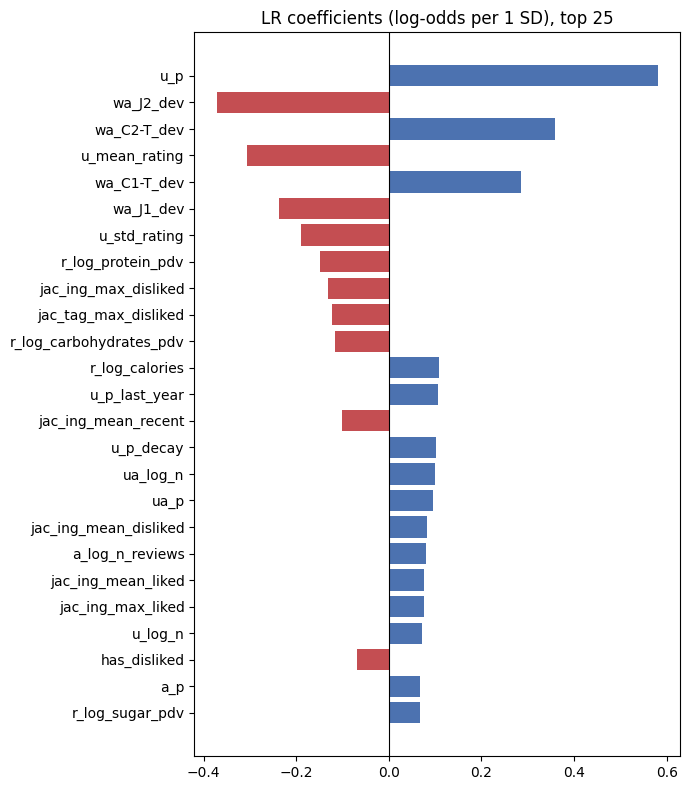

,feature,coef
0,u_p,0.5810
1,wa_J2_dev,-0.3721
2,wa_C2-T_dev,0.3577
3,u_mean_rating,-0.3065
4,wa_C1-T_dev,0.2846
5,wa_J1_dev,-0.2378
6,u_std_rating,-0.1901
7,r_log_protein_pdv,-0.1485
8,jac_ing_max_disliked,-0.1310
9,jac_tag_max_disliked,-0.1238


In [23]:
coef = lr_coefficients(lr, X_tr.columns)
coef.to_csv(RESULTS / "lr_coefficients_val.csv", index=False)
top = coef.head(25).iloc[::-1]
plt.figure(figsize=(7, 8))
plt.barh(top.feature, top.coef, color=np.where(top.coef > 0, "#4C72B0", "#C44E52"))
plt.title("LR coefficients (log-odds per 1 SD), top 25"); plt.axvline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()
coef.head(25)

### GBDT、cold vs warm、歷史長度、calibration、`rating >= 4` 敏感度

In [24]:
from sklearn.ensemble import HistGradientBoostingClassifier
gb = HistGradientBoostingClassifier(**GBDT_PARAMS).fit(X_tr.values, y_tr, sample_weight=w_tr)
preds_val["GBDT"] = gb.predict_proba(X_val.values)[:, 1]
print(f"GBDT: {gb.n_iter_} iterations, validation cold AUC = {auc(y_val[cold_val], preds_val['GBDT'][cold_val]):.4f}")

GBDT: 124 iterations, validation cold AUC = 0.7365


,cold,warm
B1,0.7252,0.7235
J1-T,0.7305,0.7351
LR,0.7335,0.7433
GBDT,0.7365,0.7432


,3-5 (n=228),6-20 (n=318),"21+ (n=5,864)"
B1,0.7433,0.7755,0.7179
J1-T,0.7481,0.7777,0.7235
LR,0.7956,0.8008,0.7255
GBDT,0.7916,0.7784,0.7322


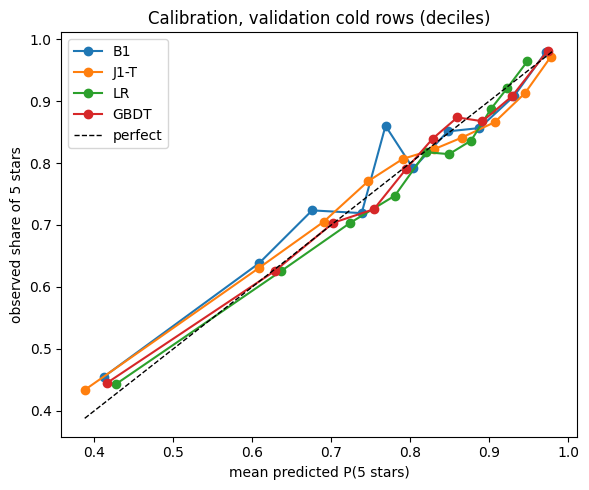

In [25]:
def by_history(snap, y, preds, mask, models):
    # AUC by the length of the user's history (rows within `mask`)
    n_hist = snap.targets.u.map(snap.history.u.value_counts()).values
    bins = {"3-5": n_hist <= 5, "6-20": (n_hist > 5) & (n_hist <= 20), "21+": n_hist > 20}
    return pd.DataFrame({f"{b} (n={(mask & m).sum():,})": {k: auc(y[mask & m], preds[k][mask & m]) for k in models}
                         for b, m in bins.items()})

def calibration_plot(ax, y, preds, models, title):
    lo, hi = 1, 0
    for k in models:
        p = preds[k]
        g = pd.DataFrame({"p": p, "y": y}).groupby(pd.qcut(p, 10, duplicates="drop"), observed=True).mean()
        ax.plot(g.p, g.y, marker="o", label=k)
        lo, hi = min(lo, g.p.min(), g.y.min()), max(hi, g.p.max(), g.y.max())
    ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="perfect")
    ax.set(title=title, xlabel="mean predicted P(5 stars)", ylabel="observed share of 5 stars"); ax.legend()

best_wa = res_val.loc[list(WA)].AUC.idxmax()
diag_models = ["B1", best_wa, "LR", "GBDT"]
cw_table = pd.DataFrame({part: {m: auc(y_val[mask], preds_val[m][mask]) for m in diag_models}
                         for part, mask in (("cold", cold_val), ("warm", ~cold_val))})
hist_table = by_history(snap_val, y_val, preds_val, cold_val, diag_models)
cw_table.to_csv(RESULTS / "val_cold_vs_warm.csv"); hist_table.to_csv(RESULTS / "val_by_history.csv")
display(cw_table, hist_table)
fig, ax = plt.subplots(figsize=(6, 5))
calibration_plot(ax, y_val[cold_val], {k: preds_val[k][cold_val] for k in diag_models}, diag_models,
                 "Calibration, validation cold rows (deciles)")
plt.tight_layout(); plt.show()

In [26]:
# label = 1[rating >= 4]: same mode / k / alpha / lambda / C, beta re-tuned
L2 = "ge4"
y2 = snap_val.targets[f"y_{L2}"].values
beta2 = float(tune_beta(snap_val, L2, cold_val, betas=BETA_GRID).beta[0])
prior2 = user_prior(snap_val, L2, beta2)
p2 = {"B1": prior2, **wa_predictions(snap_val, prior2, label=L2)}
X2 = {key: build_features(snaps_lr[key], recipes, L2, beta2, WA, LAM_USER) for key in snapshot_keys(TRAIN_MODE, "years_val")}
X2_tr, y2_tr, w2_tr = mode_train_set(TRAIN_MODE, X=X2, label=L2)
p2["LR"] = predict(fit_lr(X2_tr, y2_tr, C=C_BEST, class_weight=CW, sample_weight=w2_tr),
                   build_features(snap_val, recipes, L2, beta2, WA, LAM_USER))
print(f"negatives in validation cold rows: {(y2[cold_val] == 0).sum()}")
ev2 = {k: v[cold_val] for k, v in p2.items()}
res_ge4 = evaluate(ev2, y2[cold_val], u_val[cold_val], n_boot=N_BOOT)
cmp_ge4 = compare(ev2, "B1", y2[cold_val], u_val[cold_val], n_boot=N_BOOT)
res_ge4.to_csv(RESULTS / "val_sensitivity_ge4.csv")
pretty(res_ge4)[["AUC"]].join(pretty(cmp_ge4)[["ΔAUC", "p_not_better_AUC"]])

negatives in validation cold rows: 275


,AUC,ΔAUC,p_not_better_AUC
model,,,
B1,"0.7870 [0.7380, 0.8247]",NaN,NaN
J1,"0.7822 [0.7332, 0.8228]","-0.0048 [-0.0168, +0.0079]",0.758
J1-T,"0.7825 [0.7333, 0.8230]","-0.0045 [-0.0163, +0.0081]",0.744
J2,"0.7806 [0.7319, 0.8209]","-0.0064 [-0.0222, +0.0088]",0.799
J2-T,"0.7811 [0.7325, 0.8214]","-0.0059 [-0.0215, +0.0091]",0.776
C1,"0.7837 [0.7346, 0.8243]","-0.0033 [-0.0150, +0.0090]",0.679
C1-T,"0.7841 [0.7350, 0.8246]","-0.0029 [-0.0144, +0.0095]",0.669
C2,"0.7824 [0.7344, 0.8228]","-0.0046 [-0.0186, +0.0091]",0.736
C2-T,"0.7829 [0.7349, 0.8233]","-0.0041 [-0.0180, +0.0094]",0.726
